# Data Preparation (Revisi) — Federated Learning Diabetes Prediction

Notebook ini menyiapkan data untuk simulasi Federated Learning (FL) sesuai hasil review:

| Poin review | Perubahan di notebook ini |
|---|---|
| (2) Warm-start terpusat | **Dihapus.** Notebook ini tidak lagi melatih atau menyimpan bobot global awal. Server menginisialisasi model dengan bobot acak (seeded). |
| (3) SMOTE sebelum split | **Dipindah.** SMOTE tidak dijalankan di sini untuk data FL. SMOTE dijalankan **lokal di tiap client** (`auto_client.py`) setelah partisi. |
| (4) Validation & test terpisah | Split **70:10:20** (train : validation : test), stratified, dilakukan **sebelum** scaling/encoding. |
| Data leakage preprocessing | `ColumnTransformer` di-*fit* hanya pada partisi training. |
| Non-IID | Partisi RS_01/RS_02 sekarang benar-benar memiliki distribusi kelas yang berbeda (label skew). |

**Output:**
- `client_RS_01.npz`, `client_RS_02.npz` — data lokal tiap rumah sakit (real, belum di-SMOTE)
- `server_holdout.npz` — validation set (pemilihan model & threshold) dan test set (laporan akhir)
- `experiment_metadata.json`, `preprocessor.joblib`
- `figure_client_distribution_smote.png` — Figure 2 baru (distribusi per client sebelum/sesudah SMOTE lokal)
- (opsional) `centralized_reference_results.json` — baseline terpusat, **bukan** bagian dari pipeline FL

In [1]:
pip install tensorflow pandas matplotlib seaborn imbalanced-learn scikit-learn joblib

In [2]:
# ==========================================
# CRISP-DM PHASE 2 & 3: DATA UNDERSTANDING & PREPARATION
# ==========================================
import os
import json
import random

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from imblearn.over_sampling import SMOTE

# %matplotlib inline
sns.set_theme(style="whitegrid")

## Konfigurasi eksperimen

`SPLIT_SEED` hanya mengatur pembagian data (train/val/test dan partisi client) dan **dibuat tetap** untuk semua run.
Variasi antar-seed pada eksperimen FL (poin review 5) diatur di server dan client (`--seed`), yaitu inisialisasi bobot,
urutan batch, SMOTE lokal, dan noise. Dengan begitu perbedaan antar-scenario tidak tercampur dengan perbedaan split data.

In [3]:
DATA_PATH = "diabetes_prediction_dataset.csv"
DATASET_NAME = "Diabetes Prediction Dataset (Kaggle, 100,000 records)"

SPLIT_SEED = 42
TEST_SIZE = 0.20          # 20% test
VAL_SIZE = 0.10           # 10% validation  -> 70:10:20

# Non-IID label skew: porsi sampel training yang diberikan ke RS_01 per kelas.
# Sisanya ke RS_02. Nilai 0.70 / 0.45 menghasilkan prevalensi diabetes yang berbeda nyata antar client.
RS01_POSITIVE_SHARE = 0.70
RS01_NEGATIVE_SHARE = 0.45

RUN_CENTRALIZED_REFERENCE = True   # baseline terpusat, hanya untuk pembanding (tidak dipakai FL)

OUTPUT_DIR = "."

random.seed(SPLIT_SEED)
np.random.seed(SPLIT_SEED)

## Langkah 2: Data Understanding

In [4]:
print("LOAD DATA...")

# File CSV bisa memakai pemisah koma (versi asli Kaggle) atau titik koma (jika pernah disimpan ulang lewat Excel).
with open(DATA_PATH, "r", encoding="utf-8-sig") as f:
    header_line = f.readline()
CSV_SEP = ";" if header_line.count(";") > header_line.count(",") else ","
df = pd.read_csv(DATA_PATH, sep=CSV_SEP, encoding="utf-8-sig")

expected_columns = ["gender", "age", "hypertension", "heart_disease", "smoking_history",
                    "bmi", "HbA1c_level", "blood_glucose_level", "diabetes"]
missing_columns = [c for c in expected_columns if c not in df.columns]
if missing_columns:
    raise ValueError(f"Kolom tidak ditemukan: {missing_columns}. Kolom yang terbaca: {list(df.columns)}")

print(f"Pemisah CSV terdeteksi: '{CSV_SEP}'")
print(df.info())

LOAD DATA...
Pemisah CSV terdeteksi: ';'
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 9 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   gender               100000 non-null  object 
 1   age                  100000 non-null  float64
 2   hypertension         100000 non-null  int64  
 3   heart_disease        100000 non-null  int64  
 4   smoking_history      100000 non-null  object 
 5   bmi                  100000 non-null  float64
 6   HbA1c_level          100000 non-null  float64
 7   blood_glucose_level  100000 non-null  int64  
 8   diabetes             100000 non-null  int64  
dtypes: float64(3), int64(4), object(2)
memory usage: 6.9+ MB
None


In [5]:
n_raw = len(df)
n_duplicates = int(df.duplicated().sum())
print(f"Jumlah baris awal : {n_raw:,}")
print(f"Jumlah duplikat    : {n_duplicates:,}")

Jumlah baris awal : 100,000
Jumlah duplikat    : 3,854


- Kelas 0: 91,500 pasien (91.50%)
- Kelas 1: 8,500 pasien (8.50%)


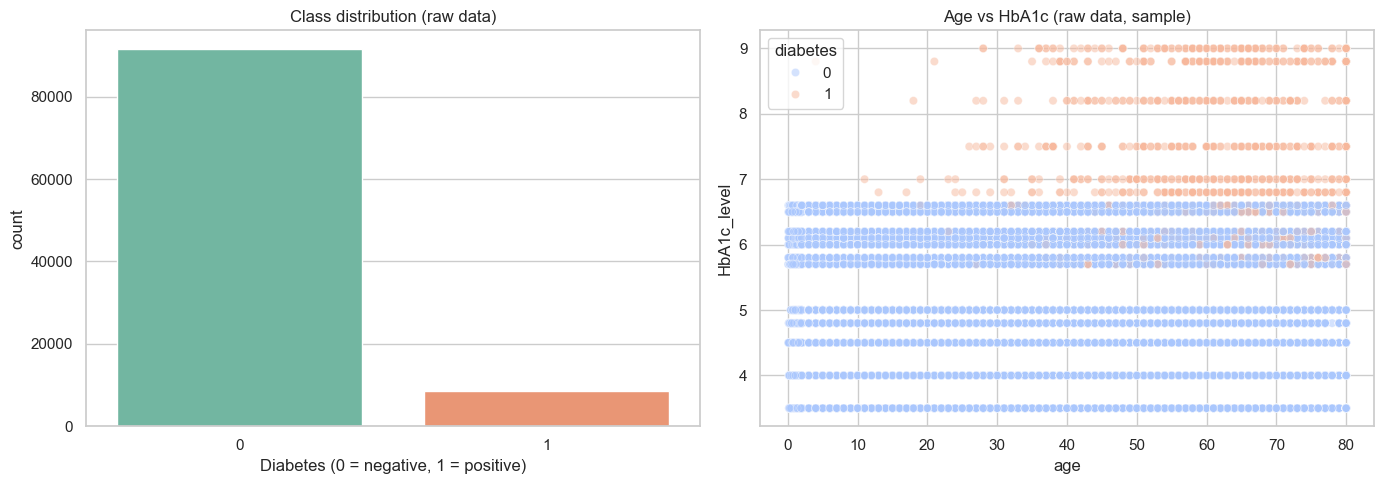

In [6]:
counts = df["diabetes"].value_counts().sort_index()
pct = df["diabetes"].value_counts(normalize=True).sort_index() * 100
for cls in counts.index:
    print(f"- Kelas {cls}: {counts[cls]:,} pasien ({pct[cls]:.2f}%)")

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sns.countplot(data=df, x="diabetes", hue="diabetes", palette="Set2", legend=False, ax=ax[0])
ax[0].set_title("Class distribution (raw data)")
ax[0].set_xlabel("Diabetes (0 = negative, 1 = positive)")
sns.scatterplot(data=df.sample(min(20000, len(df)), random_state=SPLIT_SEED),
                x="age", y="HbA1c_level", hue="diabetes", palette="coolwarm", alpha=0.5, ax=ax[1])
ax[1].set_title("Age vs HbA1c (raw data, sample)")
plt.tight_layout()
plt.show()

## Langkah 3: Data Cleaning
- Duplikat dihapus **sebelum** split, supaya baris yang identik tidak muncul sekaligus di train dan test.
- `No Info` pada `smoking_history` diubah menjadi kategori eksplisit `Unknown`.

In [7]:
df = df.drop_duplicates().reset_index(drop=True)
df["smoking_history"] = df["smoking_history"].replace("No Info", "Unknown")
print(f"Data setelah hapus duplikat: {df.shape}")

X_raw = df.drop("diabetes", axis=1)
y_all = df["diabetes"].astype(int).values

Data setelah hapus duplikat: (96146, 9)


## Langkah 4: Split Train / Validation / Test (70:10:20)

Split dilakukan **sebelum** feature engineering dan **sebelum** SMOTE, stratified berdasarkan label.
- **Validation set**: dipakai server untuk monitoring per ronde, pemilihan model terbaik, dan *threshold sweep*.
- **Test set**: hanya dipakai **sekali** di akhir setiap run untuk laporan akhir.

Kedua set berisi data **asli** (tanpa sampel sintetis).

In [8]:
X_trainval_raw, X_test_raw, y_trainval, y_test = train_test_split(
    X_raw, y_all, test_size=TEST_SIZE, random_state=SPLIT_SEED, stratify=y_all
)

val_fraction_of_trainval = VAL_SIZE / (1.0 - TEST_SIZE)
X_train_raw, X_val_raw, y_train, y_val = train_test_split(
    X_trainval_raw, y_trainval, test_size=val_fraction_of_trainval,
    random_state=SPLIT_SEED, stratify=y_trainval
)

def describe_split(name, y):
    pos = int(np.sum(y == 1))
    print(f"{name:<11} n={len(y):>7,} | positif={pos:>6,} ({pos / len(y) * 100:5.2f}%)")

describe_split("Train", y_train)
describe_split("Validation", y_val)
describe_split("Test", y_test)

Train       n= 67,301 | positif= 5,938 ( 8.82%)
Validation  n=  9,615 | positif=   848 ( 8.82%)
Test        n= 19,230 | positif= 1,696 ( 8.82%)


## Langkah 5: Feature Engineering (fit hanya pada training)

`StandardScaler` dan `OneHotEncoder` di-*fit* pada partisi training saja, lalu dipakai untuk mentransformasi validation dan test.

**Catatan untuk bagian Limitations di paper:** dalam simulasi ini scaler di-*fit* pada gabungan training data kedua client.
Pada deployment nyata, statistik scaling perlu disepakati tanpa berbagi data mentah (misalnya dengan agregasi mean/variance secara federated,
atau memakai rentang klinis yang sudah dikenal).

In [9]:
numeric_features = ["age", "bmi", "HbA1c_level", "blood_glucose_level"]
categorical_features = ["gender", "smoking_history"]
passthrough_features = ["hypertension", "heart_disease"]

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical_features),
        ("pass", "passthrough", passthrough_features),
    ]
)

X_train = preprocessor.fit_transform(X_train_raw).astype("float32")
X_val = preprocessor.transform(X_val_raw).astype("float32")
X_test = preprocessor.transform(X_test_raw).astype("float32")

ohe_names = list(preprocessor.named_transformers_["cat"].get_feature_names_out(categorical_features))
all_feature_names = numeric_features + ohe_names + passthrough_features
input_dim = X_train.shape[1]

print(f"Jumlah fitur: {input_dim}")
print(f"Fitur: {all_feature_names}")

joblib.dump(preprocessor, os.path.join(OUTPUT_DIR, "preprocessor.joblib"))
print("Preprocessor tersimpan: preprocessor.joblib")

Jumlah fitur: 15
Fitur: ['age', 'bmi', 'HbA1c_level', 'blood_glucose_level', 'gender_Female', 'gender_Male', 'gender_Other', 'smoking_history_Unknown', 'smoking_history_current', 'smoking_history_ever', 'smoking_history_former', 'smoking_history_never', 'smoking_history_not current', 'hypertension', 'heart_disease']
Preprocessor tersimpan: preprocessor.joblib


## Langkah 6: Partisi Non-IID ke RS_01 dan RS_02

Partisi dilakukan pada data training **asli** (belum di-SMOTE) dengan *label skew*:
RS_01 menerima porsi pasien diabetes yang lebih besar dibanding RS_02,
sehingga kedua rumah sakit memiliki prevalensi yang berbeda.

In [10]:
rng = np.random.default_rng(SPLIT_SEED)

pos_idx = np.where(y_train == 1)[0]
neg_idx = np.where(y_train == 0)[0]
rng.shuffle(pos_idx)
rng.shuffle(neg_idx)

n_pos_rs01 = int(round(len(pos_idx) * RS01_POSITIVE_SHARE))
n_neg_rs01 = int(round(len(neg_idx) * RS01_NEGATIVE_SHARE))

rs01_idx = np.concatenate([pos_idx[:n_pos_rs01], neg_idx[:n_neg_rs01]])
rs02_idx = np.concatenate([pos_idx[n_pos_rs01:], neg_idx[n_neg_rs01:]])
rng.shuffle(rs01_idx)
rng.shuffle(rs02_idx)

assert len(np.intersect1d(rs01_idx, rs02_idx)) == 0
assert len(rs01_idx) + len(rs02_idx) == len(y_train)

client_data = {
    "RS_01": (X_train[rs01_idx], y_train[rs01_idx]),
    "RS_02": (X_train[rs02_idx], y_train[rs02_idx]),
}

for cid, (_, yc) in client_data.items():
    describe_split(cid, yc)

RS_01       n= 31,770 | positif= 4,157 (13.08%)
RS_02       n= 35,531 | positif= 1,781 ( 5.01%)


## Langkah 7: Distribusi kelas per client sebelum dan sesudah SMOTE lokal (Figure 2 baru)

SMOTE **tidak** disimpan di file client. Setiap client menjalankan SMOTE sendiri di `auto_client.py`
hanya pada data lokalnya, sehingga tidak ada client yang menerima sampel sintetis dari data client lain.

Sel ini menjalankan SMOTE yang sama hanya untuk menghitung angka dan membuat figure.
Jumlah sampel setelah SMOTE (rasio 1:1) tidak bergantung pada seed, jadi angka di figure identik dengan yang terjadi saat training.

class                     Diabetic (1)  Non-diabetic (0)
client stage                                            
RS_01  After local SMOTE       27613.0           27613.0
       Before SMOTE             4157.0           27613.0
RS_02  After local SMOTE       33750.0           33750.0
       Before SMOTE             1781.0           33750.0


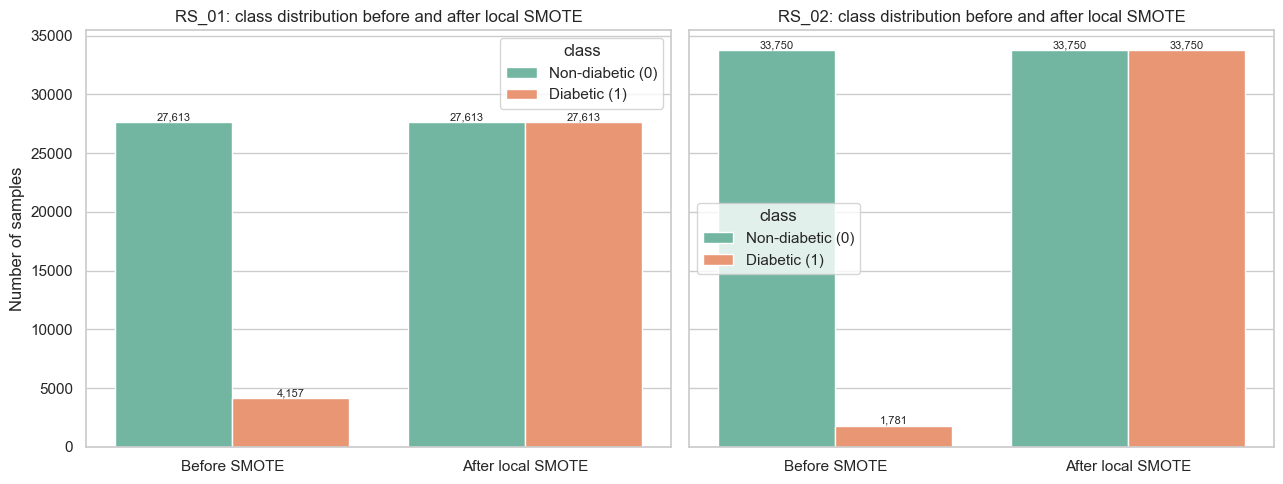

In [11]:
distribution_rows = []
for cid, (Xc, yc) in client_data.items():
    X_sm, y_sm = SMOTE(random_state=SPLIT_SEED).fit_resample(Xc, yc)
    for stage, yy in [("Before SMOTE", yc), ("After local SMOTE", y_sm)]:
        for cls in [0, 1]:
            distribution_rows.append({
                "client": cid, "stage": stage,
                "class": "Non-diabetic (0)" if cls == 0 else "Diabetic (1)",
                "count": int(np.sum(yy == cls)),
            })

dist_df = pd.DataFrame(distribution_rows)
print(dist_df.pivot_table(index=["client", "stage"], columns="class", values="count"))

fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
for ax, cid in zip(axes, ["RS_01", "RS_02"]):
    sub = dist_df[dist_df["client"] == cid]
    sns.barplot(data=sub, x="stage", y="count", hue="class", palette="Set2", ax=ax)
    ax.set_title(f"{cid}: class distribution before and after local SMOTE")
    ax.set_xlabel("")
    ax.set_ylabel("Number of samples")
    for container in ax.containers:
        ax.bar_label(container, fmt="{:,.0f}", fontsize=8)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "figure_client_distribution_smote.png"), dpi=300)
plt.show()

dist_df.to_csv(os.path.join(OUTPUT_DIR, "client_class_distribution.csv"), index=False)

## Langkah 8: Simpan data per entitas

Setiap entitas hanya mendapat file miliknya sendiri:
- `client_RS_01.npz` → hanya dibaca RS_01
- `client_RS_02.npz` → hanya dibaca RS_02
- `server_holdout.npz` → hanya dibaca server (validation + test)

Format `.npz` dipilih karena menyimpan array biner apa adanya (tanpa *precision loss* seperti CSV)
dan tidak mengeksekusi kode saat dimuat (berbeda dengan Pickle).

In [12]:
feature_names_arr = np.array(all_feature_names)

for cid, (Xc, yc) in client_data.items():
    path = os.path.join(OUTPUT_DIR, f"client_{cid}.npz")
    np.savez(path, X=Xc.astype("float32"), y=yc.astype("int32"),
             input_shape=np.array([input_dim]), feature_names=feature_names_arr)
    print(f"Tersimpan: {path}")

np.savez(
    os.path.join(OUTPUT_DIR, "server_holdout.npz"),
    X_val=X_val, y_val=y_val.astype("int32"),
    X_test=X_test, y_test=y_test.astype("int32"),
    input_shape=np.array([input_dim]), feature_names=feature_names_arr,
)
print("Tersimpan: server_holdout.npz")

def class_counts(y):
    return {"n": int(len(y)), "negative": int(np.sum(y == 0)), "positive": int(np.sum(y == 1)),
            "positive_rate": float(np.mean(y))}

experiment_metadata = {
    "dataset_name": DATASET_NAME,
    "n_raw_records": int(n_raw),
    "n_duplicates_removed": int(n_duplicates),
    "n_after_cleaning": int(len(df)),
    "split_seed": SPLIT_SEED,
    "split_ratio": {"train": 1 - TEST_SIZE - VAL_SIZE, "validation": VAL_SIZE, "test": TEST_SIZE},
    "engineered_feature_count": int(input_dim),
    "feature_names": all_feature_names,
    "preprocessing_policy": "ColumnTransformer fitted on the training partition only",
    "partition_policy": {
        "type": "label-skewed non-IID",
        "rs01_positive_share": RS01_POSITIVE_SHARE,
        "rs01_negative_share": RS01_NEGATIVE_SHARE,
    },
    "smote_policy": "Applied locally inside each client after partitioning (auto_client.py); never applied to validation or test",
    "test_set_policy": "Original (non-synthetic) held-out data; evaluated once per run after model and threshold selection on validation",
    "initialization_policy": "Random initialization on the server; no centralized pre-training",
    "class_distribution": {
        "train_total": class_counts(y_train),
        "RS_01": class_counts(client_data["RS_01"][1]),
        "RS_02": class_counts(client_data["RS_02"][1]),
        "validation": class_counts(y_val),
        "test": class_counts(y_test),
    },
}

with open(os.path.join(OUTPUT_DIR, "experiment_metadata.json"), "w") as f:
    json.dump(experiment_metadata, f, indent=2)
print("Tersimpan: experiment_metadata.json")

Tersimpan: .\client_RS_01.npz
Tersimpan: .\client_RS_02.npz
Tersimpan: server_holdout.npz
Tersimpan: experiment_metadata.json


## Langkah 9 (opsional): Centralized reference

Bagian ini **bukan** bagian dari pipeline FL dan **tidak** menghasilkan bobot apa pun untuk server.
Tujuannya hanya sebagai pembanding eksplisit di paper, diberi label *"centralized reference"*.

Dua model terpusat dilatih dengan arsitektur yang sama:
1. **Centralized (no SMOTE)** — dilatih pada data training asli.
2. **Centralized (local SMOTE pooled)** — dilatih pada gabungan data RS_01 dan RS_02 setelah SMOTE lokal masing-masing,
   yaitu data yang sama persis dengan yang dilihat client di FL.

Keduanya memakai early stopping pada validation set asli, threshold dipilih pada validation, lalu dievaluasi **sekali** pada test.

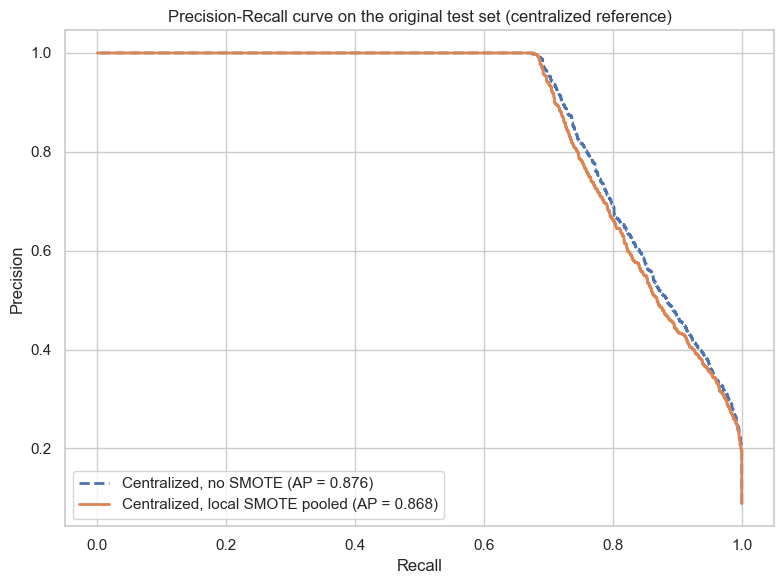

In [13]:
if RUN_CENTRALIZED_REFERENCE:
    import tensorflow as tf
    from tensorflow.keras.callbacks import EarlyStopping
    from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                                 log_loss, average_precision_score, roc_auc_score,
                                 precision_recall_curve)

    def create_model(input_dim):
        tf.keras.backend.clear_session()
        model = tf.keras.Sequential([
            tf.keras.Input(shape=(input_dim,)),
            tf.keras.layers.Dense(64, activation="relu"),
            tf.keras.layers.Dropout(0.2),
            tf.keras.layers.Dense(32, activation="relu"),
            tf.keras.layers.Dropout(0.1),
            tf.keras.layers.Dense(1, activation="sigmoid"),
        ])
        model.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss="binary_crossentropy", metrics=["accuracy"])
        return model

    def select_threshold(y_true, y_prob):
        thresholds = np.round(np.arange(0.05, 0.951, 0.01), 2)
        f1s = np.array([f1_score(y_true, (y_prob >= t).astype(int), zero_division=0) for t in thresholds])
        best = f1s.max()
        candidates = thresholds[np.isclose(f1s, best)]
        return float(candidates[np.argmin(np.abs(candidates - 0.5))])

    def metrics_at(y_true, y_prob, t):
        y_pred = (y_prob >= t).astype(int)
        return {
            "threshold": float(t),
            "accuracy": float(accuracy_score(y_true, y_pred)),
            "precision": float(precision_score(y_true, y_pred, zero_division=0)),
            "recall": float(recall_score(y_true, y_pred, zero_division=0)),
            "f1": float(f1_score(y_true, y_pred, zero_division=0)),
            "loss": float(log_loss(y_true, np.clip(y_prob, 1e-7, 1 - 1e-7), labels=[0, 1])),
            "average_precision": float(average_precision_score(y_true, y_prob)),
            "roc_auc": float(roc_auc_score(y_true, y_prob)),
        }

    X_smote_parts, y_smote_parts = [], []
    for cid, (Xc, yc) in client_data.items():
        Xs, ys = SMOTE(random_state=SPLIT_SEED).fit_resample(Xc, yc)
        X_smote_parts.append(Xs)
        y_smote_parts.append(ys)
    X_train_smote = np.vstack(X_smote_parts).astype("float32")
    y_train_smote = np.concatenate(y_smote_parts).astype("float32")

    reference_sets = {
        "centralized_no_smote": (X_train, y_train.astype("float32")),
        "centralized_local_smote_pooled": (X_train_smote, y_train_smote),
    }

    reference_results = {}
    reference_probs = {}

    for name, (Xtr, ytr) in reference_sets.items():
        tf.random.set_seed(SPLIT_SEED)
        model = create_model(input_dim)
        model.fit(
            Xtr, ytr, validation_data=(X_val, y_val.astype("float32")),
            epochs=100, batch_size=64, verbose=0,
            callbacks=[EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)],
        )
        p_val = model.predict(X_val, verbose=0).reshape(-1)
        p_test = model.predict(X_test, verbose=0).reshape(-1)
        t_star = select_threshold(y_val, p_val)
        reference_results[name] = {
            "selected_threshold_on_validation": t_star,
            "test_at_0.50": metrics_at(y_test, p_test, 0.5),
            "test_at_selected_threshold": metrics_at(y_test, p_test, t_star),
        }
        reference_probs[name] = p_test
        r = reference_results[name]["test_at_selected_threshold"]
        print(f"{name}: t*={t_star:.2f} | Acc={r['accuracy']:.4f} P={r['precision']:.4f} "
              f"R={r['recall']:.4f} F1={r['f1']:.4f} AP={r['average_precision']:.4f}")

    with open(os.path.join(OUTPUT_DIR, "centralized_reference_results.json"), "w") as f:
        json.dump(reference_results, f, indent=2)
    print("Tersimpan: centralized_reference_results.json")

    plt.figure(figsize=(8, 6))
    styles = {"centralized_no_smote": ("Centralized, no SMOTE", "--"),
              "centralized_local_smote_pooled": ("Centralized, local SMOTE pooled", "-")}
    for name, p_test in reference_probs.items():
        prec, rec, _ = precision_recall_curve(y_test, p_test)
        ap = reference_results[name]["test_at_0.50"]["average_precision"]
        label, ls = styles[name]
        plt.plot(rec, prec, linestyle=ls, linewidth=2, label=f"{label} (AP = {ap:.3f})")
    plt.title("Precision-Recall curve on the original test set (centralized reference)")
    plt.xlabel("Recall")
    plt.ylabel("Precision")
    plt.legend(loc="lower left")
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, "figure_centralized_reference_pr.png"), dpi=300)
    plt.show()

## Flowchart pipeline (revisi)

```mermaid
graph TD
    A[Load Data] --> B[Data Understanding]
    B --> C[Cleaning: drop duplicates, No Info -> Unknown]
    C --> D[Stratified split 70:10:20]
    D --> E[Fit ColumnTransformer on train only]
    E --> F[Label-skewed partition: RS_01 / RS_02]
    F --> G1[RS_01: local SMOTE -> local training]
    F --> G2[RS_02: local SMOTE -> local training]
    D --> H[Server: validation + test, original data]
    G1 --> I[FedAvg + update perturbation, random init]
    G2 --> I
    I --> J[Per-round monitoring on validation]
    J --> K[Model + threshold selection on validation]
    K --> L[Single final evaluation on test]
```

## Catatan untuk teks paper (Data Preparation)

> After removing duplicates and relabelling missing smoking information, the data were split into training, validation,
> and test partitions (70:10:20) using stratified sampling. The encoding and scaling transformations were fitted on the
> training partition only. The training partition was then divided into two simulated hospital clients, RS_01 and RS_02,
> with intentionally different class distributions. SMOTE was applied locally within each client's training subset, so
> that no client had access to synthetic samples generated from another client's data. The validation and test
> partitions contain original records only.